# Лабораторна: федеративне навчання (FedAvg) на Dry Bean Dataset

**План роботи**
1. Завантаження та первинний аналіз даних
2. Розбиття на пул для навчання, валідацію та тест
3. Softmax-регресія, реалізована вручну на NumPy
4. Централізована базова модель
5. IID та Non-IID (Dirichlet) розбиття між клієнтами
6. Клієнти, сервер і алгоритм FedAvg
7. Експерименти: вплив α, вплив числа локальних епох, порівняння моделей, персоналізація

## 0. Налаштування середовища

In [7]:
# Крок 0. Підготовка середовища
# ucimlrepo дозволяє підтягнути Dry Bean напряму, без Kaggle API
!pip install -q ucimlrepo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import copy
import time

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, log_loss, confusion_matrix

# Єдине зерно, щоб усі запуски давали однакові числа
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print(f"Середовище готове (random_state = {RANDOM_STATE})")

Середовище готове (random_state = 42)


## 1. Завантаження даних
Датасет Dry Bean: 13 611 зразків, 16 геометричних ознак зерна, 7 сортів квасолі.

In [8]:
from ucimlrepo import fetch_ucirepo

# Тягнемо Dry Bean Dataset з UCI (id = 602)
try:
    bean_repo = fetch_ucirepo(id=602)
    feature_frame = bean_repo.data.features
    target_frame = bean_repo.data.targets
    bean_df = pd.concat([feature_frame, target_frame], axis=1)
    label_col = target_frame.columns[0]
except Exception as e:
    print(f"ucimlrepo недоступний ({e}), беремо резервну копію з Excel-файлу...")
    bean_df = pd.read_excel("https://archive.ics.uci.edu/ml/machine-learning-databases/00602/DryBeanDataset.xlsx")
    label_col = 'Class'

print(f"Розмір таблиці (рядків, стовпців): {bean_df.shape}")
print(f"Назви ознак: {list(bean_df.columns[:-1])}")
print(f"Колонка з міткою сорту: '{label_col}'")
bean_df.head()

Розмір таблиці (рядків, стовпців): (13611, 17)
Назви ознак: ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRatio', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'Roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']
Колонка з міткою сорту: 'Class'


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## 2. Розвідувальний аналіз
Перевіряємо пропуски, базові статистики, баланс класів і кореляції між ознаками.

--- Перевірка на пропуски ---
0 пропущених клітинок у таблиці.

--- Короткі статистики по ознаках ---


,mean,std,min,50%,max
Area,53048.284549,29324.095717,20420.000000,44652.000000,254616.000000
Perimeter,855.283459,214.289696,524.736000,794.941000,1985.370000
MajorAxisLength,320.141867,85.694186,183.601165,296.883367,738.860154
MinorAxisLength,202.270714,44.970091,122.512653,192.431733,460.198497
AspectRatio,1.583242,0.246678,1.024868,1.551124,2.430306
Eccentricity,0.750895,0.092002,0.218951,0.764441,0.911423
ConvexArea,53768.200206,29774.915817,20684.000000,45178.000000,263261.000000
EquivDiameter,253.064220,59.177120,161.243764,238.438026,569.374358
Extent,0.749733,0.049086,0.555315,0.759859,0.866195
Solidity,0.987143,0.004660,0.919246,0.988283,0.994677


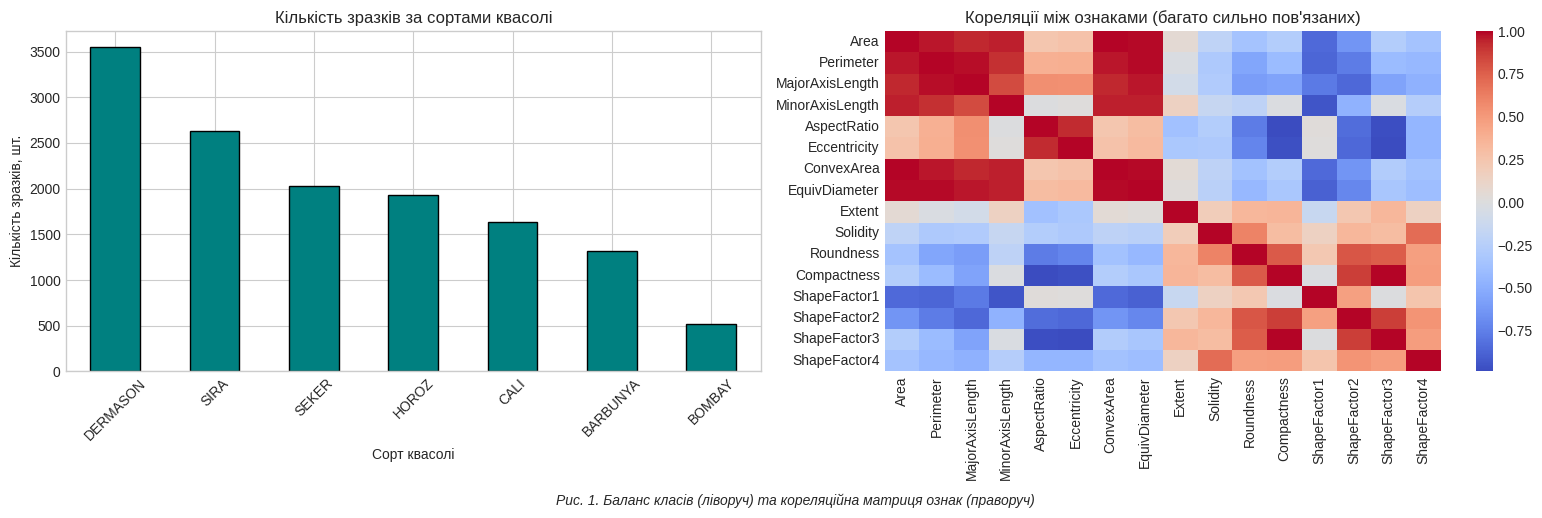

In [9]:
print("--- Перевірка на пропуски ---")
print(bean_df.isnull().sum().sum(), "пропущених клітинок у таблиці.")

print("\n--- Короткі статистики по ознаках ---")
display(bean_df.describe().T[['mean', 'std', 'min', '50%', 'max']])

# Ліворуч: баланс класів. Праворуч: теплова карта кореляцій
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

bean_df[label_col].value_counts().plot(kind='bar', ax=axes[0], color='teal', edgecolor='black')
axes[0].set_title("Кількість зразків за сортами квасолі")
axes[0].set_xlabel("Сорт квасолі")
axes[0].set_ylabel("Кількість зразків, шт.")
axes[0].tick_params(axis='x', rotation=45)

n_features = bean_df.select_dtypes(include=[np.number]).columns
corr = bean_df[n_features].corr()
sns.heatmap(corr, cmap='coolwarm', ax=axes[1], cbar=True, annot=False)
axes[1].set_title("Кореляції між ознаками (багато сильно пов'язаних)")

plt.tight_layout()
plt.figtext(0.5, -0.02,
            "Рис. 1. Баланс класів (ліворуч) та кореляційна матриця ознак (праворуч)",
            ha='center', fontsize=10, style='italic')
plt.show()

## 3. Підготовка вибірок
Глобальні валідація й тест лишаються на сервері, а решта (пул) роздається клієнтам. Скейлер навчається лише на пулі, щоб уникнути витоку інформації.

In [10]:
# Крок 2. Формуємо матрицю ознак X та вектор міток y
X_raw = bean_df.drop(columns=[label_col]).values
class_names = np.unique(bean_df[label_col])
label_to_index = {cls: idx for idx, cls in enumerate(class_names)}
y_ids = np.array([label_to_index[c] for c in bean_df[label_col]])

# (а) Відкладаємо глобальний тест: 15% даних
X_rest, X_test_raw, y_rest, y_test = train_test_split(
    X_raw, y_ids, test_size=0.15, stratify=y_ids, random_state=RANDOM_STATE
)

# (б) З решти беремо глобальну валідацію: ~12% від усього датасету
valid_share_of_rest = 0.12 / 0.85
X_pool_raw, X_valid_raw, y_pool, y_valid = train_test_split(
    X_rest, y_rest, test_size=valid_share_of_rest, stratify=y_rest, random_state=RANDOM_STATE
)

# (в) Стандартизація: параметри скейлера рахуємо тільки по тренувальному пулу
scaler = StandardScaler()
X_pool = scaler.fit_transform(X_pool_raw) # валідація й тест лише трансформуються
X_valid = scaler.transform(X_valid_raw)
X_test = scaler.transform(X_test_raw)

# One-hot мітки потрібні для крос-ентропії
n_classes = len(class_names)
def one_hot_encode(y, C):
    oh = np.zeros((y.size, C))
    oh[np.arange(y.size), y] = 1.0
    return oh

y_pool_oh = one_hot_encode(y_pool, n_classes)
y_valid_oh = one_hot_encode(y_valid, n_classes)
y_test_oh = one_hot_encode(y_test, n_classes)

print(f"Розміри підвибірок:")
print(f"• Пул для навчання (FL): {X_pool.shape[0]} зразків ({X_pool.shape[0]/len(bean_df)*100:.1f}%)")
print(f"• Глобальна валідація: {X_valid.shape[0]} зразків ({X_valid.shape[0]/len(bean_df)*100:.1f}%)")
print(f"• Глобальний тест:      {X_test.shape[0]} зразків ({X_test.shape[0]/len(bean_df)*100:.1f}%)")

Розміри підвибірок:
• Пул для навчання (FL): 9935 зразків (73.0%)
• Глобальна валідація: 1634 зразків (12.0%)
• Глобальний тест:      2042 зразків (15.0%)


## 4. Модель: багатокласова логістична регресія (softmax)
Усі обчислення векторизовані. Градієнти виведені вручну.

In [11]:
class SoftmaxClassifier:
    def __init__(self, n_features, n_classes, l2_coef=0.01):
        self.d = n_features
        self.C = n_classes
        self.l2_coef = l2_coef
        # Стартові ваги — нулі
        self.W = np.zeros((self.d, self.C), dtype=np.float64)
        self.b = np.zeros((1, self.C), dtype=np.float64)

    @staticmethod
    def softmax(Z):
        """Softmax зі стабілізацією: від кожного рядка віднімаємо його максимум."""
        Z_shifted = Z - np.max(Z, axis=1, keepdims=True)
        exp_Z = np.exp(Z_shifted)
        return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

    def class_probs(self, X):
        """Повертає матрицю ймовірностей класів P розміру (m, C)."""
        Z = np.dot(X, self.W) + self.b
        return self.softmax(Z)

    def predict_class(self, X):
        """Клас із найбільшою ймовірністю для кожного зразка."""
        P = self.class_probs(X)
        return np.argmax(P, axis=1)

    def objective(self, X, Y_oh):
        """Крос-ентропія + L2-штраф на W (зсув b не штрафуємо)."""
        m = X.shape[0]
        P = self.class_probs(X)
        eps = 1e-15
        P_clipped = np.clip(P, eps, 1.0 - eps)
        cross_entropy = -np.sum(Y_oh * np.log(P_clipped)) / m
        reg_term = (self.l2_coef / 2.0) * np.sum(self.W ** 2)
        return cross_entropy + reg_term

    def batch_gradients(self, X_batch, Y_batch_oh):
        """Градієнти dW і db одразу для всього батчу (без циклів)."""
        m = X_batch.shape[0]
        P = self.class_probs(X_batch)
        error = P - Y_batch_oh # (m, C)

        # dJ/dW = X^T (P - Y) / m + λ·W
        dW = (np.dot(X_batch.T, error) / m) + self.l2_coef * self.W
        # dJ/db = сума (P - Y) по батчу / m
        db = np.sum(error, axis=0, keepdims=True) / m
        return dW, db

    def train_minibatch(self, X, Y_oh, epochs=50, lr=0.05, batch_size=64, X_valid=None, Y_valid_oh=None):
        """Міні-батчевий SGD: кожну епоху перемішуємо дані."""
        m = X.shape[0]
        history = {'train_loss': [], 'valid_loss': []}

        for epoch in range(epochs):
            indices = np.random.permutation(m)
            X_shuffled = X[indices]
            Y_shuffled = Y_oh[indices]

            for i in range(0, m, batch_size):
                X_b = X_shuffled[i:i + batch_size]
                Y_b = Y_shuffled[i:i + batch_size]

                dW, db = self.batch_gradients(X_b, Y_b)
                self.W -= lr * dW
                self.b -= lr * db

            train_loss = self.objective(X, Y_oh)
            history['train_loss'].append(train_loss)

            if X_valid is not None and Y_valid_oh is not None:
                valid_loss = self.objective(X_valid, Y_valid_oh)
                history['valid_loss'].append(valid_loss)

        return history

    def export_params(self):
        """Віддає копію ваг (W, b)."""
        return copy.deepcopy(self.W), copy.deepcopy(self.b)

    def import_params(self, W, b):
        """Записує копію переданих ваг (W, b) у модель."""
        self.W = copy.deepcopy(W)
        self.b = copy.deepcopy(b)

## 5. Централізована базова модель
Верхня межа якості для порівняння з федеративним підходом.

=== Централізована модель: метрики на глобальному тесті ===
• accuracy       : 0.9172
• macro_f1       : 0.9303
• balanced_acc   : 0.9280
• log_loss       : 0.2737


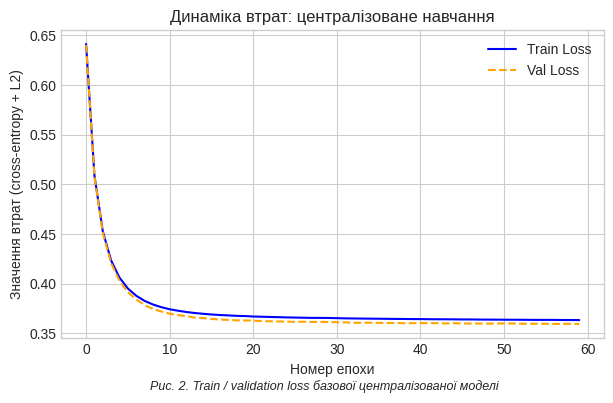

In [6]:
# Базова лінія: одна модель, що бачить весь тренувальний пул
centralized_model = SoftmaxClassifier(n_features=X_pool.shape[1],
                                             n_classes=n_classes,
                                             l2_coef=0.005)

centralized_history = centralized_model.train_minibatch(
    X=X_pool, Y_oh=y_pool_oh,
    epochs=60, lr=0.1, batch_size=128,
    X_valid=X_valid, Y_valid_oh=y_valid_oh
)

# Допоміжна функція: рахує чотири метрики якості
def score_model(model, X_eval, y_true_idx, y_true_oh):
    y_pred = model.predict_class(X_eval)
    y_prob = model.class_probs(X_eval)

    acc = accuracy_score(y_true_idx, y_pred)
    mf1 = f1_score(y_true_idx, y_pred, average='macro')
    b_acc = balanced_accuracy_score(y_true_idx, y_pred)
    ll = log_loss(y_true_idx, y_prob)
    return {
        'accuracy': acc,
        'macro_f1': mf1,
        'balanced_acc': b_acc,
        'log_loss': ll
    }

central_val_scores = score_model(centralized_model, X_valid, y_valid, y_valid_oh)
central_test_scores = score_model(centralized_model, X_test, y_test, y_test_oh)

print("=== Централізована модель: метрики на глобальному тесті ===")
for k, v in central_test_scores.items():
    print(f"• {k:15s}: {v:.4f}")

# Криві втрат по епохах
plt.figure(figsize=(7, 4))
plt.plot(centralized_history['train_loss'], label='Train Loss', color='blue')
plt.plot(centralized_history['valid_loss'], label='Val Loss', color='orange', linestyle='--')
plt.title("Динаміка втрат: централізоване навчання")
plt.xlabel("Номер епохи")
plt.ylabel("Значення втрат (cross-entropy + L2)")
plt.legend()
plt.figtext(0.5, -0.02, "Рис. 2. Train / validation loss базової централізованої моделі",
            ha='center', fontsize=9, style='italic')
plt.show()

## 6. Розбиття даних між клієнтами
Дві стратегії: IID (рівномірна) та Non-IID через розподіл Діріхле.

In [12]:
def split_iid(X, y, K, seed=RANDOM_STATE):
    """IID-розбиття: кожен клас ділиться між K клієнтами порівну."""
    np.random.seed(seed)
    client_indices = {k: [] for k in range(K)}
    class_names = np.unique(y)

    for c in class_names:
        idx_c = np.where(y == c)[0]
        np.random.shuffle(idx_c)
        splits = np.array_split(idx_c, K)
        for k in range(K):
            client_indices[k].extend(splits[k])

    assignment = {}
    for k in range(K):
        idx = np.array(client_indices[k])
        np.random.shuffle(idx)
        assignment[k] = (X[idx], y[idx])
    return assignment


def split_dirichlet(X, y, K, alpha=0.5, seed=RANDOM_STATE):
    """
    Non-IID розбиття через розподіл Діріхле Dir(alpha): що менше alpha, то більший перекіс.
    Частки кожного класу між клієнтами беруться з Dirichlet-вибірки.
    """
    np.random.seed(seed)
    n_classes = len(np.unique(y))
    client_indices = {k: [] for k in range(K)}

    for c in range(n_classes):
        idx_c = np.where(y == c)[0]
        np.random.shuffle(idx_c)

        # Випадкові частки для цього класу
        proportions = np.random.dirichlet(np.repeat(alpha, K))
        # Частки -> кількість зразків
        counts = (proportions * len(idx_c)).astype(int)

        # Роздаємо залишок, що з'явився через округлення
        diff = len(idx_c) - counts.sum()
        for i in range(diff):
            counts[i % K] += 1

        start = 0
        for k in range(K):
            end = start + counts[k]
            client_indices[k].extend(idx_c[start:end])
            start = end

    assignment = {}
    for k in range(K):
        idx = np.array(client_indices[k])
        np.random.shuffle(idx)
        assignment[k] = (X[idx], y[idx])
    return assignment

### Візуалізація Non-IID розбиття (демонстрація, α = 0.3)

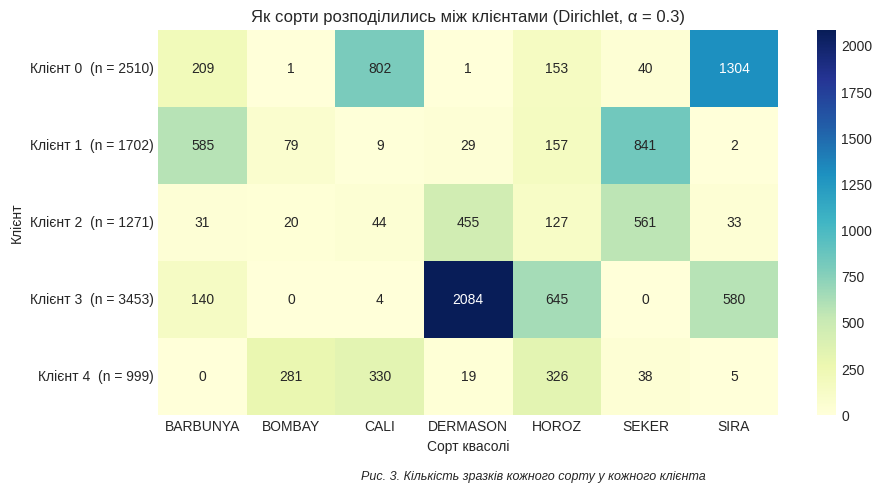

In [13]:
n_clients = 5
alpha_preview = 0.3
dirichlet_demo_clients = split_dirichlet(X_pool, y_pool, K=n_clients, alpha=alpha_preview)

# Рахуємо, скільки зразків кожного класу потрапило до кожного клієнта
class_count_matrix = np.zeros((n_clients, n_classes))
for k in range(n_clients):
    _, y_k = dirichlet_demo_clients[k]
    for c in range(n_classes):
        class_count_matrix[k, c] = np.sum(y_k == c)

plt.figure(figsize=(10, 5))
sns.heatmap(class_count_matrix, annot=True, fmt='.0f', cmap='YlGnBu',
            xticklabels=class_names, yticklabels=[f"Клієнт {k}  (n = {len(dirichlet_demo_clients[k][1])})" for k in range(n_clients)])
plt.title(f"Як сорти розподілились між клієнтами (Dirichlet, α = {alpha_preview})")
plt.xlabel("Сорт квасолі")
plt.ylabel("Клієнт")
plt.figtext(0.5, -0.02, "Рис. 3. Кількість зразків кожного сорту у кожного клієнта",
            ha='center', fontsize=9, style='italic')
plt.show()

## 7. Федеративне навчання: клієнт, сервер, FedAvg

In [14]:
class FLClient:
    """Клієнт FL: бачить лише власну частину даних."""
    def __init__(self, client_id, X_local, y_local, n_classes, l2_coef=0.01):
        self.client_id = client_id
        self.X = X_local
        self.y = y_local
        self.y_oh = one_hot_encode(y_local, n_classes)
        self.n_samples = len(y_local)
        self.model = SoftmaxClassifier(X_local.shape[1], n_classes, l2_coef=l2_coef)

    def local_update(self, global_W, global_b, local_epochs=5, lr=0.05, batch_size=64):
        # Крок 1: беремо актуальні глобальні ваги
        self.model.import_params(global_W, global_b)
        # Крок 2: дотреновуємо локально E епох
        self.model.train_minibatch(self.X, self.y_oh, epochs=local_epochs, lr=lr, batch_size=batch_size)
        # Крок 3: віддаємо оновлені ваги серверу
        return self.model.export_params()


class FLServer:
    """Сервер: тримає глобальну модель і лише агрегує ваги клієнтів."""
    def __init__(self, n_features, n_classes, l2_coef=0.01):
        self.global_model = SoftmaxClassifier(n_features, n_classes, l2_coef=l2_coef)

    def fedavg_merge(self, client_weights, client_sample_sizes):
        """FedAvg: середнє ваг клієнтів, зважене на розмір їхніх вибірок n_k."""
        total_samples = sum(client_sample_sizes)
        new_W = np.zeros_like(self.global_model.W)
        new_b = np.zeros_like(self.global_model.b)

        for (W_k, b_k), n_k in zip(client_weights, client_sample_sizes):
            weight_ratio = n_k / total_samples
            new_W += weight_ratio * W_k
            new_b += weight_ratio * b_k

        self.global_model.import_params(new_W, new_b)


def simulate_fedavg(parts_by_client, n_features, n_classes,
                             rounds=25, local_epochs=5, lr=0.05, batch_size=64,
                             X_valid=None, y_valid=None, y_valid_oh=None):
    """Симуляція повного циклу FedAvg: раунди комунікації між сервером і клієнтами."""
    K = len(parts_by_client)
    clients = [
        FLClient(k, parts_by_client[k][0], parts_by_client[k][1], n_classes)
        for k in range(K)
    ]
    server = FLServer(n_features, n_classes)

    round_valid_accs = []
    round_valid_losses = []

    for r in range(rounds):
        client_updates = []
        sample_sizes = []

        # Знімок поточних глобальних ваг
        g_W, g_b = server.global_model.export_params()

        # Кожен клієнт тренується локально
        for client in clients:
            w_k = client.local_update(g_W, g_b, local_epochs=local_epochs, lr=lr, batch_size=batch_size)
            client_updates.append(w_k)
            sample_sizes.append(client.n_samples)

        # Сервер усереднює отримані ваги
        server.fedavg_merge(client_updates, sample_sizes)

        # Моніторимо якість на глобальній валідації
        valid_loss = server.global_model.objective(X_valid, y_valid_oh)
        valid_pred = server.global_model.predict_class(X_valid)
        valid_acc = accuracy_score(y_valid, valid_pred)

        round_valid_losses.append(valid_loss)
        round_valid_accs.append(valid_acc)

    return server.global_model, round_valid_losses, round_valid_accs, clients

## 8. Експеримент 1: вплив неоднорідності (α)

=== Експеримент 1: як неоднорідність даних впливає на FedAvg ===
Готово: α=5.0 | Test Acc = 0.9153 | Macro F1 = 0.9276
Готово: α=1.0 | Test Acc = 0.9128 | Macro F1 = 0.9268
Готово: α=0.3 | Test Acc = 0.8609 | Macro F1 = 0.8153


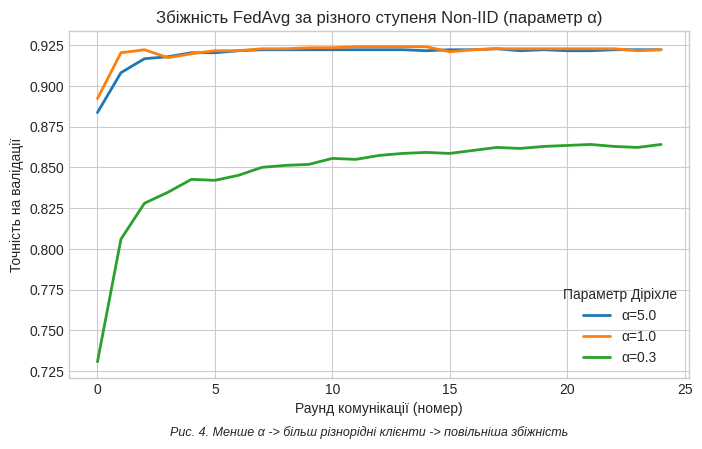

In [15]:
alpha_grid = [5.0, 1.0, 0.3]
alpha_study_scores = {}
alpha_study_curves = {}

print("=== Експеримент 1: як неоднорідність даних впливає на FedAvg ===")
for a in alpha_grid:
    client_parts = split_dirichlet(X_pool, y_pool, K=5, alpha=a, seed=RANDOM_STATE)
    fl_model, valid_losses, valid_accs, _ = simulate_fedavg(
        client_parts, X_pool.shape[1], n_classes,
        rounds=25, local_epochs=5, lr=0.08, batch_size=64,
        X_valid=X_valid, y_valid=y_valid, y_valid_oh=y_valid_oh
    )

    # Підсумкова оцінка — тільки на глобальному тесті
    metrics = score_model(fl_model, X_test, y_test, y_test_oh)
    alpha_study_scores[f"Dirichlet α={a}"] = metrics
    alpha_study_curves[f"α={a}"] = valid_accs
    print(f"Готово: α={a:3.1f} | Test Acc = {metrics['accuracy']:.4f} | Macro F1 = {metrics['macro_f1']:.4f}")

# Криві збіжності за раундами
plt.figure(figsize=(8, 4.5))
for lbl, acc_hist in alpha_study_curves.items():
    plt.plot(acc_hist, label=lbl, linewidth=2)
plt.title("Збіжність FedAvg за різного ступеня Non-IID (параметр α)")
plt.xlabel("Раунд комунікації (номер)")
plt.ylabel("Точність на валідації")
plt.legend(title="Параметр Діріхле")
plt.figtext(0.5, -0.02, "Рис. 4. Менше α -> більш різнорідні клієнти -> повільніша збіжність",
            ha='center', fontsize=9, style='italic')
plt.show()

## 9. Експеримент 2: вплив числа локальних епох E

=== Експеримент 2: скільки локальних епох E краще (α = 0.3) ===
Готово: E= 1 | Test Acc = 0.8928 | Macro F1 = 0.8792
Готово: E= 5 | Test Acc = 0.8599 | Macro F1 = 0.8162
Готово: E=10 | Test Acc = 0.8188 | Macro F1 = 0.7146


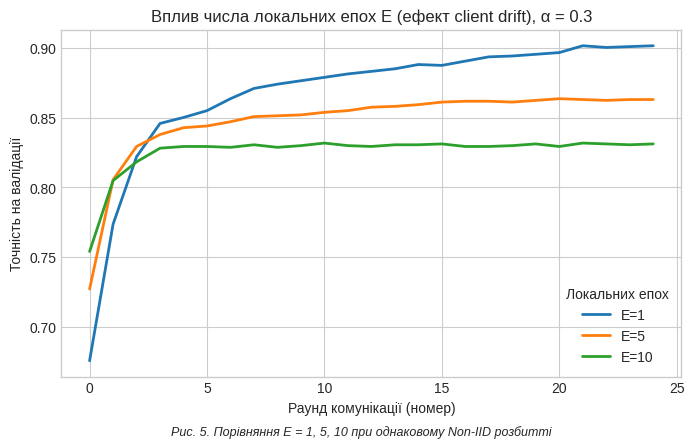

In [16]:
local_epochs_grid = [1, 5, 10]
epochs_study_scores = {}
epochs_study_curves = {}

# Фіксуємо сильно перекошений розподіл (alpha = 0.3)
noniid_parts = split_dirichlet(X_pool, y_pool, K=5, alpha=0.3, seed=RANDOM_STATE)

print("=== Експеримент 2: скільки локальних епох E краще (α = 0.3) ===")
for E in local_epochs_grid:
    fl_model, valid_losses, valid_accs, _ = simulate_fedavg(
        noniid_parts, X_pool.shape[1], n_classes,
        rounds=25, local_epochs=E, lr=0.08, batch_size=64,
        X_valid=X_valid, y_valid=y_valid, y_valid_oh=y_valid_oh
    )

    metrics = score_model(fl_model, X_test, y_test, y_test_oh)
    epochs_study_scores[f"Local E={E}"] = metrics
    epochs_study_curves[f"E={E}"] = valid_accs
    print(f"Готово: E={E:2d} | Test Acc = {metrics['accuracy']:.4f} | Macro F1 = {metrics['macro_f1']:.4f}")

plt.figure(figsize=(8, 4.5))
for lbl, acc_hist in epochs_study_curves.items():
    plt.plot(acc_hist, label=lbl, linewidth=2)
plt.title("Вплив числа локальних епох E (ефект client drift), α = 0.3")
plt.xlabel("Раунд комунікації (номер)")
plt.ylabel("Точність на валідації")
plt.legend(title="Локальних епох")
plt.figtext(0.5, -0.02, "Рис. 5. Порівняння E = 1, 5, 10 при однаковому Non-IID розбитті",
            ha='center', fontsize=9, style='italic')
plt.show()

## 10. Порівняння: централізована vs FedAvg vs локальні моделі

In [17]:
# Для порівняння: кожен клієнт тренує модель сам, без обміну вагами
local_scores = []
for k in range(5):
    X_k, y_k = noniid_parts[k]
    y_k_oh = one_hot_encode(y_k, n_classes)
    solo_model = SoftmaxClassifier(X_k.shape[1], n_classes, l2_coef=0.01)
    solo_model.train_minibatch(X_k, y_k_oh, epochs=30, lr=0.08, batch_size=64)
    local_scores.append(score_model(solo_model, X_test, y_test, y_test_oh))

comparison_table = pd.DataFrame([
    {
        'Модель': 'Централізована (весь пул)',
        **central_test_scores
    },
    {
        'Модель': 'FedAvg, майже IID (α = 5.0)',
        **alpha_study_scores['Dirichlet α=5.0']
    },
    {
        'Модель': 'FedAvg, сильний Non-IID (α = 0.3)',
        **alpha_study_scores['Dirichlet α=0.3']
    },
    {
        'Модель': 'Локальні моделі клієнтів без FL (середнє, α = 0.3)',
        'accuracy': np.mean([m['accuracy'] for m in local_scores]),
        'macro_f1': np.mean([m['macro_f1'] for m in local_scores]),
        'balanced_acc': np.mean([m['balanced_acc'] for m in local_scores]),
        'log_loss': np.mean([m['log_loss'] for m in local_scores])
    }
])

print("=== Підсумкове порівняння моделей на глобальному тесті ===")
display(comparison_table)

=== Підсумкове порівняння моделей на глобальному тесті ===


,Модель,accuracy,macro_f1,balanced_acc,log_loss
0,Централізована (весь пул),0.917238,0.930319,0.927999,0.273653
1,"FedAvg, майже IID (α = 5.0)",0.915279,0.927593,0.924520,0.321278
2,"FedAvg, сильний Non-IID (α = 0.3)",0.860921,0.815305,0.805697,0.456733
3,"Локальні моделі клієнтів без FL (середнє, α = ...",0.625759,0.545867,0.638329,1.620516


## 11. Експеримент 3: персоналізація глобальної моделі

In [18]:
print("=== Експеримент 3: персоналізація глобальної моделі ===")
# Заново тренуємо глобальну модель на Non-IID (α = 0.3)
final_fl_model, _, _, fitted_clients = simulate_fedavg(
    noniid_parts, X_pool.shape[1], n_classes,
    rounds=20, local_epochs=3, lr=0.08, batch_size=64,
    X_valid=X_valid, y_valid=y_valid, y_valid_oh=y_valid_oh
)

g_W, g_b = final_fl_model.export_params()
tuned_accs = []
global_on_local_accs = []

for client in fitted_clients:
    # (1) Як глобальна модель працює на даних конкретного клієнта
    p_glob = final_fl_model.predict_class(client.X)
    global_on_local_accs.append(accuracy_score(client.y, p_glob))

    # (2) Персоналізація: старт із глобальних ваг + 2 епохи локального донавчання
    tuned_model = SoftmaxClassifier(client.X.shape[1], n_classes, l2_coef=0.01)
    tuned_model.import_params(g_W, g_b)
    tuned_model.train_minibatch(client.X, client.y_oh, epochs=2, lr=0.05, batch_size=32)

    p_pers = tuned_model.predict_class(client.X)
    tuned_accs.append(accuracy_score(client.y, p_pers))

personalization_table = pd.DataFrame({
    'Клієнт': [f"Клієнт №{k}" for k in range(len(fitted_clients))],
    'Acc глобальної моделі': global_on_local_accs,
    'Acc після персоналізації (+2 епохи)': tuned_accs
})
display(personalization_table)

=== Експеримент 3: персоналізація глобальної моделі ===


,Клієнт,Acc глобальної моделі,Acc після персоналізації (+2 епохи)
0,Клієнт №0,0.895219,0.951793
1,Клієнт №1,0.886016,0.959459
2,Клієнт №2,0.856019,0.941778
3,Клієнт №3,0.876629,0.935418
4,Клієнт №4,0.793794,0.963964
